<a href="https://colab.research.google.com/github/3bdo-Yahya/NileSpark/blob/pipeline%2Fdata-processing/pipeline/Nasa_Space_Apps.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
import io
import zipfile

import numpy as np
import pandas as pd
import requests
from sklearn.ensemble import IsolationForest

COUNTRIES = {
    "Egypt": {
        "modis": "https://firms.modaps.eosdis.nasa.gov/data/download/DL_FIRE_M-C61_847061.zip",
        "viirs": "https://firms.modaps.eosdis.nasa.gov/data/download/DL_FIRE_SV-C2_847076.zip",
    },

    "Canada": {
        "modis": "https://firms.modaps.eosdis.nasa.gov/data/download/DL_FIRE_M-C61_847279.zip",
        "viirs": "https://firms.modaps.eosdis.nasa.gov/data/download/DL_FIRE_SV-C2_847280.zip"
    },

   "Brazil": {
        "modis": "https://firms.modaps.eosdis.nasa.gov/data/download/DL_FIRE_M-C61_847265.zip",
        "viirs": "https://firms.modaps.eosdis.nasa.gov/data/download/DL_FIRE_SV-C2_847342.zip"
    },
}


In [17]:
STD_COLS = ["latitude", "longitude", "acq_date", "acq_time", "frp", "sensor"]


def read_firms_zip(url):
    r = requests.get(url)
    r.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(r.content)) as z:
        name = next(n for n in z.namelist() if n.endswith(".csv"))
        return pd.read_csv(z.open(name))


def clean_modis(raw):
    df = raw[raw["type"] == 0].copy()
    df["confidence"] = pd.to_numeric(df["confidence"], errors="coerce")
    df = df[df["confidence"] >= 30]
    df["sensor"] = "MODIS"
    return df[STD_COLS].drop_duplicates()


def clean_viirs(raw):
    df = raw[raw["type"] == 0].copy()
    df = df[df["confidence"].astype(str).str.lower() != "l"]
    df["sensor"] = "VIIRS"
    return df[STD_COLS].drop_duplicates()


def load_country(name, urls):
    modis = clean_modis(read_firms_zip(urls["modis"]))
    viirs = clean_viirs(read_firms_zip(urls["viirs"]))

    df = pd.concat([modis, viirs], ignore_index=True)
    df["acq_date"] = pd.to_datetime(df["acq_date"])
    df["year"] = df["acq_date"].dt.year
    df["month"] = df["acq_date"].dt.month
    df["country"] = name
    return df

In [18]:
def monthly_table(df):
    m = df.groupby(["year", "month", "sensor"]).size().unstack(fill_value=0).reset_index()
    m.columns.name = None
    for s in ("MODIS", "VIIRS"):
        if s not in m:
            m[s] = 0

    # timeline runs from the first MODIS month to the last detection
    start = df.loc[df["sensor"] == "MODIS", "acq_date"].min().replace(day=1)
    end = df["acq_date"].max().replace(day=1)
    idx = pd.date_range(start, end, freq="MS")
    timeline = pd.DataFrame({"year": idx.year, "month": idx.month})

    return timeline.merge(m, on=["year", "month"], how="left").fillna({"MODIS": 0, "VIIRS": 0})


def harmonize(m):
    overlap = m[m["year"] >= 2012]
    factor = overlap["VIIRS"].sum() / max(overlap["MODIS"].sum(), 1)

    m["modis_harmonized"] = m["MODIS"] * factor
    m["harmonized_count"] = np.where(m["year"] >= 2012, m["VIIRS"], m["modis_harmonized"])
    return m, factor


def validate(m):
    # fit the ratio on 2012-2018, check it on 2019-2024
    calib = m[m["year"].between(2012, 2018)]
    test = m[m["year"].between(2019, 2024)]
    f = calib["VIIRS"].sum() / max(calib["MODIS"].sum(), 1)

    total_err = abs(test["MODIS"].sum() * f - test["VIIRS"].sum()) / max(test["VIIRS"].sum(), 1) * 100
    corr = test["MODIS"].corr(test["VIIRS"], method="spearman")
    return f, corr, total_err


def add_anomalies(m):
    med = m.groupby("month")["harmonized_count"].median()
    m["historical_median"] = m["month"].map(med)

    m["anomaly_pct"] = (m["harmonized_count"] - m["historical_median"]) / m["historical_median"].clip(lower=1) * 100
    m["trend_3m"] = m["anomaly_pct"].rolling(3, min_periods=1).mean()

    X = m[["anomaly_pct", "trend_3m"]]
    iso = IsolationForest(contamination=0.05, random_state=42)
    m["ai_flag"] = iso.fit_predict(X)  # -1 = anomaly
    m["ai_score"] = -iso.decision_function(X)

    m["severity"] = np.select(
        [(m["ai_flag"] == -1) & (m["anomaly_pct"] > 0), m["ai_flag"] == -1, m["anomaly_pct"] > 25],
        ["Extreme Anomaly", "Unusually Low", "Elevated"],
        default="Normal",
    )
    return m


def qc(m, name):
    assert not m[["year", "month"]].duplicated().any(), f"{name}: duplicate months"
    assert np.isfinite(m[["harmonized_count", "anomaly_pct", "ai_score"]]).all().all(), f"{name}: NaN or inf"
    assert (m["harmonized_count"] >= 0).all(), f"{name}: negative counts"
    assert m["MODIS"].sum() > 0 and m["VIIRS"].sum() > 0, f"{name}: one sensor has no data"
    assert m["year"].min() <= 2001 and m["year"].max() >= 2024, f"{name}: timeline too short"

    empty_modis = ((m["year"] < 2012) & (m["MODIS"] == 0)).sum()
    empty_viirs = ((m["year"] >= 2012) & (m["VIIRS"] == 0)).sum()
    print(f"{name} QC ok | empty months: MODIS {empty_modis}, VIIRS {empty_viirs}")

In [19]:
monthly_by_country = {}
validation = {}

for name, urls in COUNTRIES.items():
    df = load_country(name, urls)
    df.to_parquet(f"{name.lower().replace(' ', '_')}_clean.parquet", index=False)

    m = monthly_table(df)
    validation[name] = validate(m)
    m, factor = harmonize(m)
    m = add_anomalies(m)
    m["country"] = name
    m["date"] = pd.to_datetime(m[["year", "month"]].assign(day=1))
    qc(m, name)

    monthly_by_country[name] = m
    print(f"{name}: {len(df):,} clean detections | VIIRS/MODIS factor {factor:.2f}x")

all_monthly = pd.concat(monthly_by_country.values(), ignore_index=True)
all_monthly.to_csv("monthly_anomalies.csv", index=False)
all_monthly.tail(10)

Egypt QC ok | empty months: MODIS 0, VIIRS 0
Egypt: 143,849 clean detections | VIIRS/MODIS factor 12.02x
Canada QC ok | empty months: MODIS 0, VIIRS 0
Canada: 6,485,302 clean detections | VIIRS/MODIS factor 5.47x
Brazil QC ok | empty months: MODIS 4, VIIRS 0
Brazil: 16,571,265 clean detections | VIIRS/MODIS factor 922.06x


,year,month,MODIS,VIIRS,modis_harmonized,harmonized_count,historical_median,anomaly_pct,trend_3m,ai_flag,ai_score,severity,country,date
860,2024,3,221.0,30555.0,2.037759e+05,30555.0,27787.5,9.959514,59.305307,1,-0.231817,Normal,Brazil,2024-03-01
861,2024,4,507.0,11338.0,4.674860e+05,11338.0,18642.0,-39.180345,23.501586,1,-0.216296,Normal,Brazil,2024-04-01
862,2024,5,1140.0,32895.0,1.051152e+06,32895.0,35577.5,-7.539878,-12.253570,1,-0.233297,Normal,Brazil,2024-05-01
863,2024,6,221.0,70905.0,2.037759e+05,70905.0,40030.5,77.127440,10.135739,1,-0.219972,Elevated,Brazil,2024-06-01
864,2024,7,7.0,74450.0,6.454441e+03,74450.0,51719.0,43.950966,37.846176,1,-0.233902,Elevated,Brazil,2024-07-01
865,2024,8,0.0,490512.0,0.000000e+00,490512.0,131724.5,272.377196,131.151867,1,-0.124630,Elevated,Brazil,2024-08-01
866,2024,9,12.0,602522.0,1.106476e+04,602522.0,240644.0,150.378983,155.569048,1,-0.158324,Elevated,Brazil,2024-09-01
867,2024,10,7.0,220725.0,6.454441e+03,220725.0,144750.5,52.486520,158.414233,1,-0.184098,Elevated,Brazil,2024-10-01
868,2024,11,8.0,117785.0,7.376504e+03,117785.0,65069.0,81.015537,94.627013,1,-0.214371,Elevated,Brazil,2024-11-01
869,2024,12,0.0,57100.0,0.000000e+00,57100.0,27376.0,108.576856,80.692971,1,-0.209153,Elevated,Brazil,2024-12-01


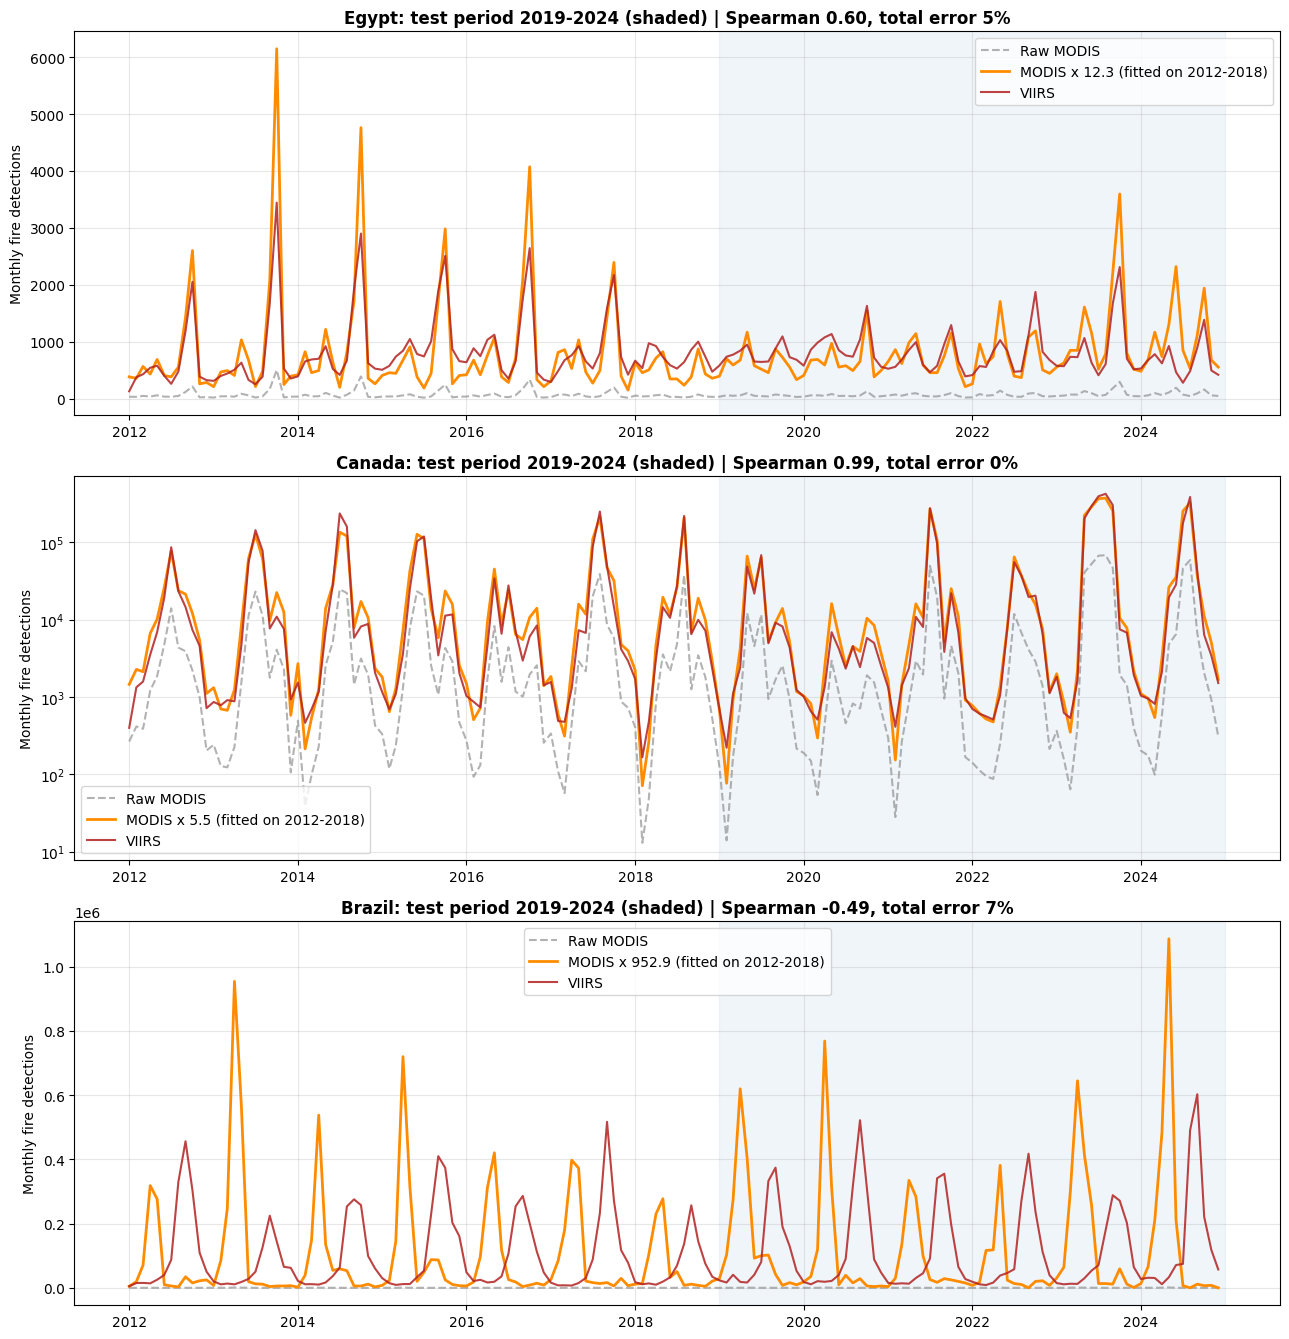

In [20]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(len(monthly_by_country), 1, figsize=(13, 4.5 * len(monthly_by_country)), squeeze=False)

for ax, (name, m) in zip(axes[:, 0], monthly_by_country.items()):
    f, corr, err = validation[name]
    d = m[m["year"] >= 2012]

    ax.plot(d["date"], d["MODIS"], "--", color="gray", alpha=0.6, label="Raw MODIS")
    ax.plot(d["date"], d["MODIS"] * f, color="darkorange", lw=2, label=f"MODIS x {f:.1f} (fitted on 2012-2018)")
    ax.plot(d["date"], d["VIIRS"], color="firebrick", alpha=0.85, lw=1.5, label="VIIRS")
    ax.axvspan(pd.Timestamp("2019-01-01"), pd.Timestamp("2024-12-31"), color="steelblue", alpha=0.08)

    ax.set_title(f"{name}: test period 2019-2024 (shaded) | correlation {corr:.2f}, total error {err:.0f}%", fontweight="bold")
    ax.set_ylabel("Monthly fire detections")
    ax.legend()
    ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig("validation_chart.png", dpi=300)
plt.show()

## Methodology

**Data.** We use NASA satellite fire detections from two sensors: MODIS (2000 onward) and VIIRS (2012 onward). Only vegetation fires are counted. Gas flares and other fixed heat sources are removed, along with low-confidence detections.

**Putting the two sensors on one scale.** VIIRS detects smaller fires, so it reports more of them than MODIS. We multiply MODIS counts by a factor measured for each country in the years when both sensors were running (about 12x for Egypt and 5.5x for Canada). From 2012 on we use the real VIIRS counts.

**Checking the scaling.** We measured the factor on 2012-2018 and tested it on 2019-2024. For Egypt, the totals differ by 5%, and months that are high in one sensor are mostly high in the other (rank correlation 0.72). For Canada the match is closer (0.99).

**Finding unusual months.** For every month we compare the number of fires with the typical (median) count for the same calendar month over all years. More than 25% above typical is marked "Elevated". An Isolation Forest model then looks at each month's deviation and its 3-month trend, and marks the most unusual ones: "Extreme Anomaly" for unusually high months and "Unusually Low" for unusually quiet ones. It flags about 5% of months, so a flag means "unusual for this country", not "disaster".

**Limits.**
- We count detected fires, not burned area.
- Clouds or satellite gaps can hide fires.
- Before 2012 the numbers come from scaled MODIS, which can exaggerate the biggest peaks (visible in Egypt's chart), so early spikes are less certain than recent ones.
- Results are best for comparing a country with its own past, not countries with each other.